# Heart Disease Prediction Using Machine Learning

In [1]:
import warnings, os, json
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold,
                                     cross_validate, cross_val_predict, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              VotingClassifier)
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay, precision_recall_curve)

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
DATA_PATH = "heart.csv"          # keep heart.csv in the same folder as this notebook
os.makedirs("figures", exist_ok=True)

## 1. Load the data and audit its quality
Feature meaning (UCI Cleveland heart-disease data): `age`, `sex` (1 = male), `cp` chest-pain type (0–3), `trestbps` resting blood pressure, `chol` cholesterol (mg/dl), `fbs` fasting blood sugar > 120 mg/dl (1 = yes), `restecg` resting ECG (0–2), `thalach` max heart rate, `exang` exercise-induced angina (1 = yes), `oldpeak` ST depression, `slope` ST slope (0–2), `ca` major vessels coloured by fluoroscopy (0–3), `thal` thalassemia (1–3).

In [2]:
raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)
print("Missing values:", int(raw.isnull().sum().sum()))
raw.head()

Shape: (1025, 14)
Missing values: 0


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [3]:
n_dup = raw.duplicated().sum()
print(f"Total rows            : {len(raw)}")
print(f"Exact duplicate rows  : {n_dup}  ({n_dup/len(raw):.1%})")
print(f"Unique patients       : {len(raw) - n_dup}")
print()
print("Out-of-range / invalid codes:")
print("  ca   == 4 :", int((raw.ca == 4).sum()), " (valid range is 0-3)")
print("  thal == 0 :", int((raw.thal == 0).sum()), " (valid codes are 1, 2, 3)")

Total rows            : 1025
Exact duplicate rows  : 723  (70.5%)
Unique patients       : 302

Out-of-range / invalid codes:
  ca   == 4 : 18  (valid range is 0-3)
  thal == 0 : 7  (valid codes are 1, 2, 3)


### 1.1 Demonstration: why the original accuracy could not be trusted
The original notebook split the *duplicated* data. Below we reproduce that exact split and count how many test rows have an identical copy in the training set. A model that has already "seen" the test rows will score unrealistically well — a Random Forest can simply memorise them.

In [4]:
Xr, yr = raw.drop(columns="target"), raw["target"]
xtr_o, xte_o, ytr_o, yte_o = train_test_split(Xr, yr, test_size=0.2, stratify=yr, random_state=2)

train_rows = set(map(tuple, xtr_o.values))
leaked = sum(tuple(r) in train_rows for r in xte_o.values)
print(f"Test rows that also appear in the training set: {leaked} of {len(xte_o)} ({leaked/len(xte_o):.0%})")

lr_o = LogisticRegression().fit(xtr_o, ytr_o)
rf_o = RandomForestClassifier(random_state=0).fit(xtr_o, ytr_o)
print(f"Original-style Logistic Regression test accuracy : {lr_o.score(xte_o, yte_o):.3f}")
print(f"Original-style Random Forest test accuracy       : {rf_o.score(xte_o, yte_o):.3f}   <- 100% = memorisation, not learning")

Test rows that also appear in the training set: 202 of 205 (99%)
Original-style Logistic Regression test accuracy : 0.805
Original-style Random Forest test accuracy       : 1.000   <- 100% = memorisation, not learning


## 2. Data cleaning

In [5]:
df = raw.drop_duplicates().reset_index(drop=True)
df.loc[df["ca"] == 4, "ca"] = np.nan       # invalid -> missing (imputed later, inside the pipeline)
df.loc[df["thal"] == 0, "thal"] = np.nan   # invalid -> missing

print("Clean shape:", df.shape)
print("Missing after marking invalid codes:\n", df.isnull().sum()[lambda s: s > 0].to_string())
df.describe().T.round(2)

Clean shape: (302, 14)
Missing after marking invalid codes:
 ca      4
thal    2


,count,mean,std,min,25%,50%,75%,max
age,302.0,54.42,9.05,29.0,48.00,55.5,61.00,77.0
sex,302.0,0.68,0.47,0.0,0.00,1.0,1.00,1.0
cp,302.0,0.96,1.03,0.0,0.00,1.0,2.00,3.0
trestbps,302.0,131.60,17.56,94.0,120.00,130.0,140.00,200.0
chol,302.0,246.50,51.75,126.0,211.00,240.5,274.75,564.0
fbs,302.0,0.15,0.36,0.0,0.00,0.0,0.00,1.0
restecg,302.0,0.53,0.53,0.0,0.00,1.0,1.00,2.0
thalach,302.0,149.57,22.90,71.0,133.25,152.5,166.00,202.0
exang,302.0,0.33,0.47,0.0,0.00,0.0,1.00,1.0
oldpeak,302.0,1.04,1.16,0.0,0.00,0.8,1.60,6.2


In [6]:
check = df.groupby("target")[["thalach", "oldpeak", "exang", "ca", "age"]].mean().round(2)
check.index = ["target = 0", "target = 1"]
check

,thalach,oldpeak,exang,ca,age
target = 0,139.10,1.59,0.55,1.15,56.60
target = 1,158.38,0.59,0.14,0.27,52.59


In [7]:
df["disease"] = 1 - df["target"]
print(df["disease"].value_counts().rename({1: "disease", 0: "healthy"}).to_string())

disease
healthy    164
disease    138


## 3. Exploratory data analysis

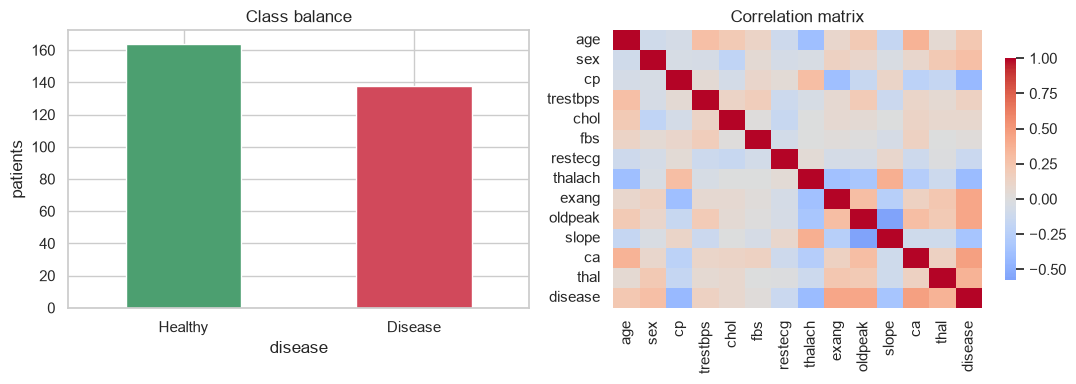

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df["disease"].map({0: "Healthy", 1: "Disease"}).value_counts().plot.bar(ax=axes[0], color=["#4C9F70", "#D1495B"], rot=0)
axes[0].set_title("Class balance"); axes[0].set_ylabel("patients")

sns.heatmap(df.drop(columns="target").corr(), cmap="coolwarm", center=0, ax=axes[1], cbar_kws={"shrink": .8})
axes[1].set_title("Correlation matrix")
plt.tight_layout(); plt.savefig("figures/01_balance_correlation.png", dpi=130); plt.show()

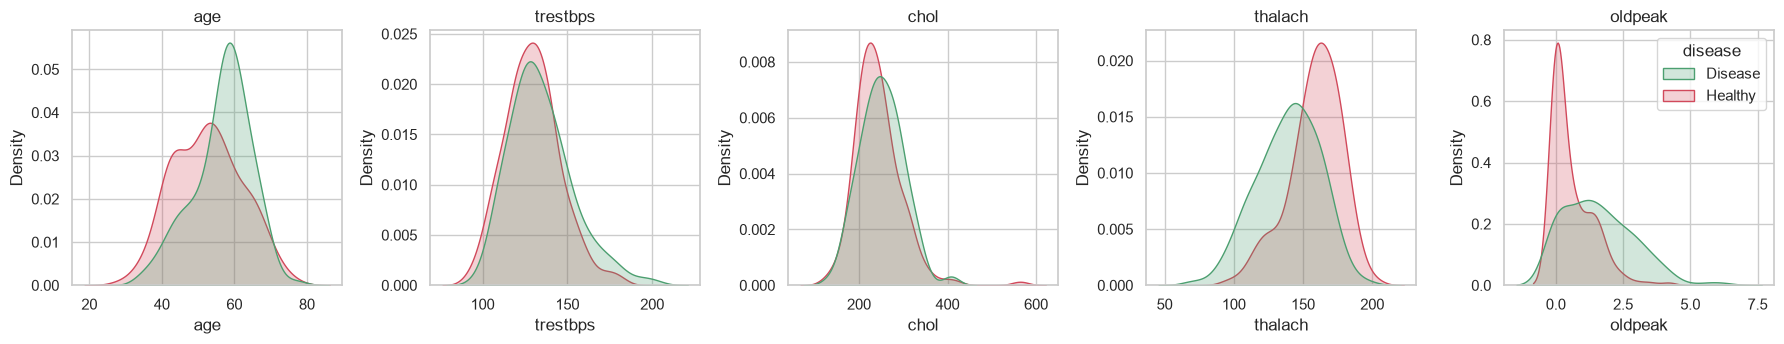

In [9]:
num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
fig, axes = plt.subplots(1, 5, figsize=(18, 3.6))
for ax, c in zip(axes, num_cols):
    sns.kdeplot(data=df, x=c, hue=df["disease"].map({0: "Healthy", 1: "Disease"}), fill=True, common_norm=False, ax=ax,
                palette=["#4C9F70", "#D1495B"], legend=(c == num_cols[-1]))
    ax.set_title(c)
plt.tight_layout(); plt.savefig("figures/02_numeric_distributions.png", dpi=130); plt.show()

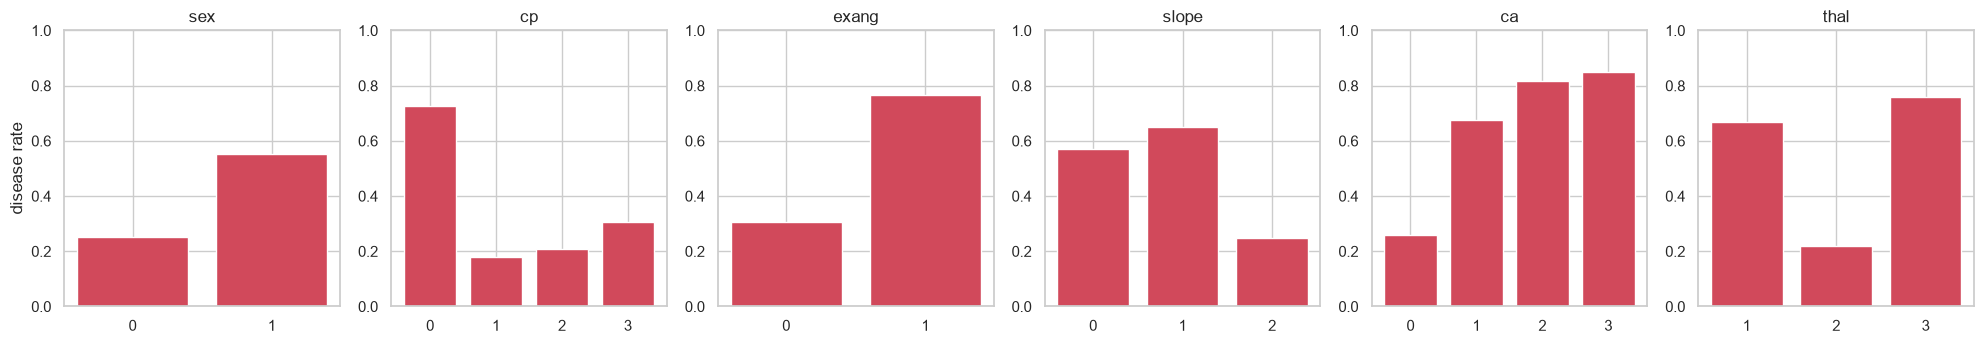

In [10]:
cat_cols_plot = ["sex", "cp", "exang", "slope", "ca", "thal"]
fig, axes = plt.subplots(1, 6, figsize=(20, 3.6))
for ax, c in zip(axes, cat_cols_plot):
    rate = df.groupby(c)["disease"].mean()
    ax.bar(rate.index.astype(int).astype(str), rate.values, color="#D1495B")
    ax.set_title(c); ax.set_ylim(0, 1); ax.set_ylabel("disease rate" if c == "sex" else "")
plt.tight_layout(); plt.savefig("figures/03_disease_rate_by_category.png", dpi=130); plt.show()

## 4. Train / test split and preprocessing pipeline

In [11]:
FEATURES = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
            "thalach", "exang", "oldpeak", "slope", "ca", "thal"]
NUM  = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]
CAT  = ["cp", "restecg", "slope", "thal"]
BIN  = ["sex", "fbs", "exang"]

X = df[FEATURES]
y = df["disease"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Duplicate rows between train and test:",
      len(set(map(tuple, X_train.values)) & set(map(tuple, X_test.values))))

def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), CAT),
        ("bin", "passthrough", BIN),
    ])

def make_pipe(model):
    return Pipeline([("pre", make_preprocessor()), ("model", model)])

Train: (241, 13)  Test: (61, 13)
Duplicate rows between train and test: 0


## 5. Compare eight algorithms with repeated stratified cross-validation

In [12]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "KNN":                 KNeighborsClassifier(n_neighbors=15),
    "SVM (RBF)":           SVC(probability=True, random_state=SEED),
    "Decision Tree":       DecisionTreeClassifier(max_depth=4, random_state=SEED),
    "Random Forest":       RandomForestClassifier(n_estimators=300, random_state=SEED),
    "Gradient Boosting":   GradientBoostingClassifier(random_state=SEED),
    "Naive Bayes":         GaussianNB(),
    "Neural Net (MLP)":    MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=3000, random_state=SEED),
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
rows = []
for name, m in models.items():
    s = cross_validate(make_pipe(m), X_train, y_train, cv=cv,
                       scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])
    rows.append({"Model": name,
                 "Accuracy": s["test_accuracy"].mean(), "Acc. std": s["test_accuracy"].std(),
                 "Precision": s["test_precision"].mean(), "Recall": s["test_recall"].mean(),
                 "F1": s["test_f1"].mean(), "ROC-AUC": s["test_roc_auc"].mean()})
cv_results = pd.DataFrame(rows).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
cv_results.round(3)

,Model,Accuracy,Acc. std,Precision,Recall,F1,ROC-AUC
0,Random Forest,0.839,0.053,0.858,0.785,0.816,0.907
1,Logistic Regression,0.838,0.059,0.849,0.791,0.816,0.907
2,SVM (RBF),0.834,0.054,0.870,0.752,0.804,0.903
3,KNN,0.808,0.053,0.843,0.712,0.770,0.889
4,Gradient Boosting,0.810,0.047,0.809,0.773,0.787,0.885
5,Naive Bayes,0.813,0.064,0.832,0.742,0.777,0.879
6,Neural Net (MLP),0.815,0.065,0.816,0.776,0.792,0.863
7,Decision Tree,0.776,0.054,0.783,0.718,0.743,0.787


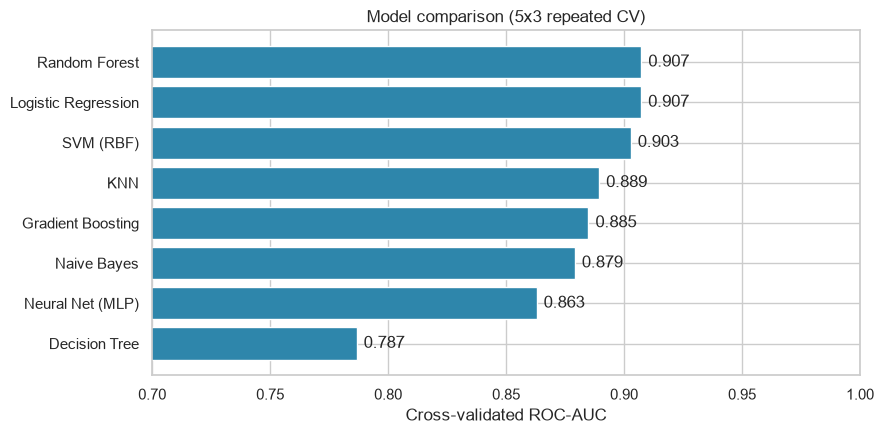

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.5))
order = cv_results.sort_values("ROC-AUC")
ax.barh(order["Model"], order["ROC-AUC"], color="#2E86AB")
for i, v in enumerate(order["ROC-AUC"]):
    ax.text(v + 0.003, i, f"{v:.3f}", va="center")
ax.set_xlim(0.7, 1.0); ax.set_xlabel("Cross-validated ROC-AUC"); ax.set_title("Model comparison (5x3 repeated CV)")
plt.tight_layout(); plt.savefig("figures/04_model_comparison.png", dpi=130); plt.show()

## 6. Hyper-parameter tuning
The three strongest model families are tuned with `GridSearchCV` (5-fold, scored by ROC-AUC) on the **training set only**.

In [14]:
grids = {
    "Logistic Regression": (LogisticRegression(max_iter=2000),
        {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10], "model__penalty": ["l2"]}),
    "SVM (RBF)": (SVC(probability=True, random_state=SEED),
        {"model__C": [0.1, 0.3, 1, 3, 10], "model__gamma": ["scale", 0.01, 0.03, 0.1]}),
    "Random Forest": (RandomForestClassifier(random_state=SEED),
        {"model__n_estimators": [200, 400], "model__max_depth": [3, 5, None],
         "model__min_samples_leaf": [1, 3, 5]}),
}
tuned = {}
for name, (m, grid) in grids.items():
    gs = GridSearchCV(make_pipe(m), grid, cv=5, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)
    tuned[name] = gs.best_estimator_
    print(f"{name:20s} best CV ROC-AUC = {gs.best_score_:.3f}   params = { {k.replace('model__',''): v for k, v in gs.best_params_.items()} }")

Logistic Regression  best CV ROC-AUC = 0.917   params = {'C': 0.1, 'penalty': 'l2'}
SVM (RBF)            best CV ROC-AUC = 0.915   params = {'C': 1, 'gamma': 0.01}
Random Forest        best CV ROC-AUC = 0.920   params = {'max_depth': 5, 'min_samples_leaf': 3, 'n_estimators': 400}


### 6.1 Soft-voting ensemble of the tuned models

In [15]:
ensemble = make_pipe(VotingClassifier(
    estimators=[("lr", tuned["Logistic Regression"].named_steps["model"]),
                ("svm", tuned["SVM (RBF)"].named_steps["model"]),
                ("rf", tuned["Random Forest"].named_steps["model"])],
    voting="soft"))
tuned["Voting Ensemble"] = ensemble

summary = []
for name, est in tuned.items():
    s = cross_validate(est, X_train, y_train, cv=cv, scoring=["accuracy", "roc_auc"])
    summary.append({"Model": name, "CV Accuracy": s["test_accuracy"].mean(), "CV ROC-AUC": s["test_roc_auc"].mean()})
summary = pd.DataFrame(summary).sort_values("CV ROC-AUC", ascending=False).reset_index(drop=True)
print(summary.round(3).to_string())
best_name = summary.loc[0, "Model"]
print("Selected model (by cross-validated ROC-AUC on training data):", best_name)

                 Model  CV Accuracy  CV ROC-AUC
0        Random Forest        0.846       0.914
1      Voting Ensemble        0.857       0.913
2            SVM (RBF)        0.855       0.911
3  Logistic Regression        0.856       0.910
Selected model (by cross-validated ROC-AUC on training data): Random Forest


## 7. Final evaluation 


In [16]:
final_model = tuned[best_name].fit(X_train, y_train)
proba = final_model.predict_proba(X_test)[:, 1]
pred  = (proba >= 0.5).astype(int)

metrics = {
    "Accuracy":  accuracy_score(y_test, pred),
    "Precision": precision_score(y_test, pred),
    "Recall (sensitivity)": recall_score(y_test, pred),
    "Specificity": recall_score(y_test, pred, pos_label=0),
    "F1": f1_score(y_test, pred),
    "ROC-AUC": roc_auc_score(y_test, proba),
}
print(f"Test patients: {len(y_test)}")
print(pd.Series(metrics).round(3).to_string())
print("\nTrain accuracy (for over-fitting check):", round(accuracy_score(y_train, final_model.predict(X_train)), 3))

Test patients: 61
Accuracy                0.787
Precision               0.778
Recall (sensitivity)    0.750
Specificity             0.818
F1                      0.764
ROC-AUC                 0.897

Train accuracy (for over-fitting check): 0.913


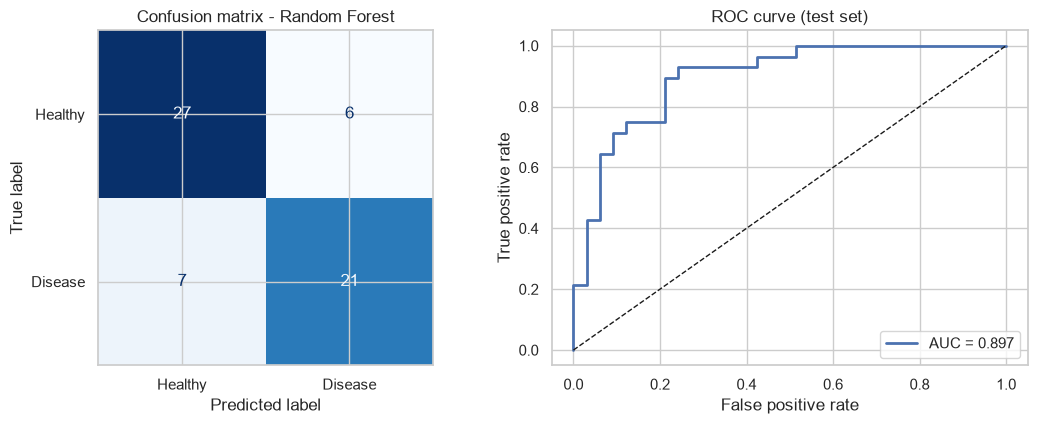

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Healthy", "Disease"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"Confusion matrix - {best_name}")

fpr, tpr, _ = roc_curve(y_test, proba)
axes[1].plot(fpr, tpr, lw=2, label=f"AUC = {metrics['ROC-AUC']:.3f}")
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate"); axes[1].set_title("ROC curve (test set)")
axes[1].legend(loc="lower right")
plt.tight_layout(); plt.savefig("figures/05_confusion_roc.png", dpi=130); plt.show()

In [18]:
# With only ~61 test patients, one number is not enough: bootstrap a 95% confidence interval.
rng = np.random.default_rng(SEED)
yt, yp = y_test.values, pred
accs = []
for _ in range(2000):
    idx = rng.integers(0, len(yt), len(yt))
    accs.append((yt[idx] == yp[idx]).mean())
lo, hi = np.percentile(accs, [2.5, 97.5])
print(f"Test accuracy = {metrics['Accuracy']:.3f}   95% bootstrap CI = [{lo:.3f}, {hi:.3f}]")

Test accuracy = 0.787   95% bootstrap CI = [0.689, 0.885]


## 8. Decision Threshold Analysis

In [19]:
oof = cross_val_predict(tuned[best_name], X_train, y_train, cv=5, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
ok = np.where(rec[:-1] >= 0.90)[0]
chosen = float(thr[ok[-1]]) if len(ok) else 0.5
print(f"Chosen threshold (>= 90% recall on training out-of-fold): {chosen:.2f}")

pred_t = (proba >= chosen).astype(int)
cmp = pd.DataFrame({
    "Threshold 0.50": [accuracy_score(y_test, pred), recall_score(y_test, pred), precision_score(y_test, pred), recall_score(y_test, pred, pos_label=0)],
    f"Threshold {chosen:.2f}": [accuracy_score(y_test, pred_t), recall_score(y_test, pred_t), precision_score(y_test, pred_t), recall_score(y_test, pred_t, pos_label=0)],
}, index=["Accuracy", "Recall (sensitivity)", "Precision", "Specificity"])
print(cmp.round(3).to_string())
print("False negatives at 0.50 :", int(((pred == 0) & (y_test.values == 1)).sum()))
print(f"False negatives at {chosen:.2f}:", int(((pred_t == 0) & (y_test.values == 1)).sum()))

Chosen threshold (>= 90% recall on training out-of-fold): 0.33
                      Threshold 0.50  Threshold 0.33
Accuracy                       0.787           0.787
Recall (sensitivity)           0.750           0.929
Precision                      0.778           0.703
Specificity                    0.818           0.667
False negatives at 0.50 : 7
False negatives at 0.33: 2


## 9. Feature Importance

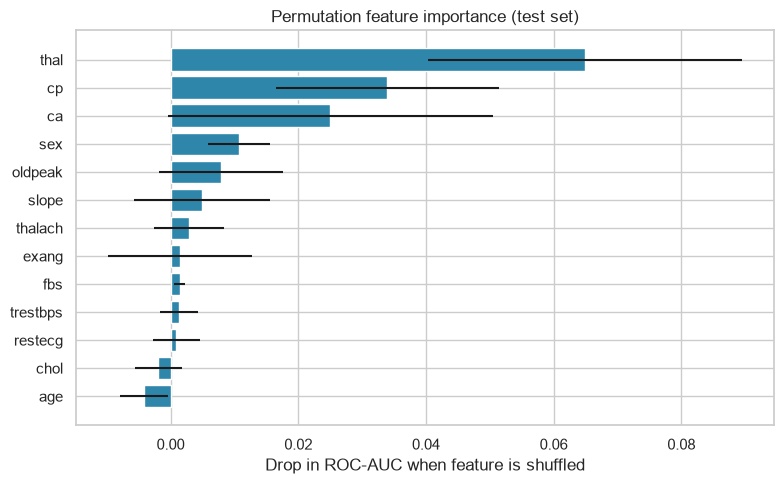

Top 5 features: ['thal', 'cp', 'ca', 'sex', 'oldpeak']


In [20]:
pi = permutation_importance(final_model, X_test, y_test, n_repeats=30, random_state=SEED, scoring="roc_auc")
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index, imp.values, xerr=pd.Series(pi.importances_std, index=FEATURES)[imp.index].values, color="#2E86AB")
ax.set_xlabel("Drop in ROC-AUC when feature is shuffled"); ax.set_title("Permutation feature importance (test set)")
plt.tight_layout(); plt.savefig("figures/06_feature_importance.png", dpi=130); plt.show()
print("Top 5 features:", list(imp.index[::-1][:5]))

In [21]:
# Interpretable view: odds ratios from a tuned Logistic Regression
lr_pipe = tuned["Logistic Regression"].fit(X_train, y_train)
names = lr_pipe.named_steps["pre"].get_feature_names_out()
coefs = pd.Series(lr_pipe.named_steps["model"].coef_[0], index=[n.split("__")[1] for n in names])
odds = np.exp(coefs).sort_values(ascending=False).round(2).rename("odds ratio")
print("Odds ratio > 1 raises predicted risk of disease, < 1 lowers it (numeric features are per 1 std-dev):\n")
print(odds.to_string())

Odds ratio > 1 raises predicted risk of disease, < 1 lowers it (numeric features are per 1 std-dev):

ca             2.21
cp_0.0         1.86
thal_3.0       1.67
exang          1.63
sex            1.56
oldpeak        1.52
slope_1.0      1.32
trestbps       1.15
restecg_0.0    1.09
chol           1.09
fbs            1.04
restecg_2.0    1.01
age            0.98
slope_0.0      0.97
thal_1.0       0.96
cp_1.0         0.93
restecg_1.0    0.90
cp_3.0         0.79
slope_2.0      0.78
thalach        0.74
cp_2.0         0.74
thal_2.0       0.62


## 10. Save Model and Make Predictions

In [22]:
final_model.fit(X_train, y_train)
joblib.dump({"model": final_model, "features": FEATURES, "threshold": chosen}, "heart_model.joblib")
print("Saved -> heart_model.joblib")

LIMITS = {  # (min, max) used for validation
    "age": (1, 120), "sex": (0, 1), "cp": (0, 3), "trestbps": (60, 260), "chol": (80, 700),
    "fbs": (0, 1), "restecg": (0, 2), "thalach": (50, 250), "exang": (0, 1),
    "oldpeak": (0, 10), "slope": (0, 2), "ca": (0, 3), "thal": (1, 3),
}

def predict_patient(age, sex, cp, trestbps, chol, fbs, restecg, thalach, exang, oldpeak, slope, ca, thal,
                    threshold=chosen):
    """fbs: 1 if fasting blood sugar > 120 mg/dl else 0.  thal: 1=fixed defect, 2=normal, 3=reversible defect (dataset coding)."""
    vals = dict(age=age, sex=sex, cp=cp, trestbps=trestbps, chol=chol, fbs=fbs, restecg=restecg,
                thalach=thalach, exang=exang, oldpeak=oldpeak, slope=slope, ca=ca, thal=thal)
    for k, v in vals.items():
        lo_, hi_ = LIMITS[k]
        if not (lo_ <= v <= hi_):
            raise ValueError(f"{k}={v} is outside the valid range {lo_}-{hi_}")
    p = float(final_model.predict_proba(pd.DataFrame([vals])[FEATURES])[0, 1])
    verdict = "HIGH risk - heart disease likely, consult a doctor" if p >= threshold else "LOW risk - heart disease not indicated"
    return p, verdict

def interactive_predict():
    """Run this in a terminal/notebook to enter a patient's values one by one (not auto-run)."""
    ask = lambda msg, cast, k: cast(input(f"{msg} [{LIMITS[k][0]}-{LIMITS[k][1]}]: "))
    p, v = predict_patient(
        age=ask("Age", int, "age"), sex=ask("Sex (0=female, 1=male)", int, "sex"),
        cp=ask("Chest pain type (0-3)", int, "cp"), trestbps=ask("Resting blood pressure (mm Hg)", int, "trestbps"),
        chol=ask("Cholesterol (mg/dl)", int, "chol"), fbs=ask("Fasting blood sugar > 120 mg/dl? (1=yes, 0=no)", int, "fbs"),
        restecg=ask("Resting ECG (0-2)", int, "restecg"), thalach=ask("Max heart rate achieved", int, "thalach"),
        exang=ask("Exercise-induced angina (1=yes, 0=no)", int, "exang"), oldpeak=ask("ST depression (oldpeak)", float, "oldpeak"),
        slope=ask("Slope of peak exercise ST segment (0-2)", int, "slope"),
        ca=ask("Major vessels coloured by fluoroscopy (0-3)", int, "ca"),
        thal=ask("Thalassemia (1=fixed defect, 2=normal, 3=reversible defect)", int, "thal"))
    print(f"Estimated probability of heart disease: {p:.1%}\n{v}")

# Demo with two real test patients (one healthy, one with disease)
for label in (0, 1):
    row = X_test[y_test == label].iloc[0]
    p, v = predict_patient(**row.to_dict())
    print(f"Actual: {'Disease' if label else 'Healthy':8s} -> P(disease) = {p:.1%}  |  {v}")

Saved -> heart_model.joblib
Actual: Healthy  -> P(disease) = 26.4%  |  LOW risk - heart disease not indicated
Actual: Disease  -> P(disease) = 94.2%  |  HIGH risk - heart disease likely, consult a doctor


## 11. Conclusion

- Compared multiple machine learning algorithms using cross-validation.
- Evaluated model performance using accuracy, precision, recall, F1-score and ROC-AUC.
- Used permutation importance to identify influential features.
- Saved the trained model for making predictions.

### Limitations and Future Work

- The dataset contains a limited number of unique patient records.
- Model performance needs validation on external datasets.
- Future improvements include SHAP explanations, probability calibration and a Streamlit web interface.

**Note:** This project is for educational purposes only and is not intended for medical diagnosis.